---
# Python resources for the Virtual Observatory
## Some use cases of astroquery, Vizier and PyVO
---

**Authored by** Ricardo Rizzo (ISDEFE, SVO collaborator)

**Revised/approved:** [Spanish Virtual Observatory](https://svo.cab.inta-csic.es)

**Creation date:** October 25, 2025

**Updated:** November, 2025

This tutorial presents an introductory use of Python tools aimed to profit the Virtual Observatory (VO) capabilities.

The tutorial assumes that the user:
- has sufficient knowledge of Python 3.
- is able to manage python notebooks and Google colab platform.
- has a general idea about Virtual Observatory (VO).
- does **not** need previous knowledge about existing catalogs or other VO resources.
---


# Overview: the tools

The tutorial focuses on the use of the packages ```Vizier```, ```astroquery```, and ```PyVO```. These packages are considered a bridge between the VO resources and the powerful and versatile Python language.

It follows a "_learning by doing_" approach and is structured around a series of examples which make use of the necessary packages.

Therefore, it is **NOT** a complete reference to all the capabilities of the packages, but a starting guide to use them. Some external references are included when appropriate.

## Why using VizieR
- VizieR (https://vizier.cds.unistra.fr/) provides the most complete library of published astronomical catalogues (25800+ up to November 2025).
- It is a "live" repository, with verified and enriched data from surveys, catalogs and tables.
- Its content is accessible by multiple online interfaces and desktop applications.
- There are a number of query tools that allow the user to select relevant data tables and to extract records matching a given criteria.
- It has several mirrors worldwide.
- Most of its capabilities are integrated in ```astroquery.vizier```, an affiliated package of ```astroquery```.
- Reference: [https://astroquery.readthedocs.io/en/latest/vizier/vizier.html](https://astroquery.readthedocs.io/en/latest/vizier/vizier.html)

## What about astroquery
- astroquery is **THE** query tool in Python for astronomy.
- It has an excellent management of tables in all their formats, particularly VOTables.
- astroquery includes easy access to VizieR functionalities through its convenience functions, which are added to the astroquery.vizier methods and functions.
- Reference: [https://astroquery.readthedocs.io/en/latest/](https://astroquery.readthedocs.io/en/latest/)

## When to go to PyVO
- PyVO works as an "extension" of astropy (https://www.astropy.org), the most popular collection of software packages written in Python for use in astronomy.
- PyVO includes several methods and functions to facilitate an easy access to the mostly commonly used VO protocols.
- When used in combination with numpy, pandas, matplotlib, etc., other high functionalities are possible.
- Reference: [https://github.com/astropy/pyvo](https://github.com/astropy/pyvo)

# Overview: the protocols
The examples developed in this tutorial are based on a client-server structure.

The communication between the tools (on the client side) and the servers (which provide access to data and metadata on the server side) is done through protocols.

IVOA has defined a number of protocols which are necessary to successfully communicate servers and clients.

In this tutorial we use some of the most popular VO protocols, briefly described below.

## Simple Cone Search protocol (SCS)
This protocol is used to provide results from queries to one or more **tables**, based on a given position on the sky.

The parameters needed are therefore very simple: position (RA, Dec) and a search radius (SR) in degrees around it.

Some packages and utilities may include wrappers to use SCS with other parameters, like a search based on a source name.

Reference: [https://www.ivoa.net/documents/latest/ConeSearch.html](https://www.ivoa.net/documents/latest/ConeSearch.html)

## Simple Image Access protocol (SIA)
This protocol provides capabilities for the discovery, description, access, and retrieval of multi-dimensional **image** datasets, including 2D images as well as datacubes of three or more dimensions.

The queries using this protocols need, _as a minimum_, the same parameters as the SCS. In most cases, some of the fields in the metadata are also searchable, which adds flexibility (and complexity!) to the queries.

The resulting VOTables are lists of metadata on images on the queried service/s.

**Reference:** [https://www.ivoa.net/documents/SIA/20151223/index.html](https://www.ivoa.net/documents/SIA/20151223/index.html)


## Simple Spectral Access protocol (SSA)

This protocol works very similar to SIA. Results from a query are VOTable whose metadata (some of them searchable) describe information about **spectra** which can be analised and downloaded.

The resulting spectra from a SSA query are VOTables, which can later be converted to other formats.

**Reference:** [https://www.ivoa.net/documents/SSA/](https://www.ivoa.net/documents/SSA/)

## Table Access Protocol (TAP)

This protocol also allow the client to access tables and catalogs, but
with more powerful capabilities in comparison with the precedent ones.

Its robustness relies in highly flexible specifications to the query, which are derived from the implementation of **ADQL** [(Astronomical Data Query Language)](https://www.ivoa.net/documents/ADQL/20180112/PR-ADQL-2.1-20180112.html).

ADQL is a tailored query language based on SQL. The client can consult to the server adding more conditions to the query. In this way, the queries are faster than using the previous protocols because filtering is made on the server side.

**Reference:** [https://www.ivoa.net/documents/TAP/](https://www.ivoa.net/documents/TAP/)



---
# Install the necessary packages

The packages needed for this tutorial are indicated in the file ```requirements.txt```.


In [ ]:
# Download the list of needed packages from the Zenodo tutorial
! wget -qO requirements.txt https://zenodo.org/records/17533386/files/requirements.txt?download=1
# Load requirements.txt from owner's drive
! pip install -r requirements.txt

The following packages are necessary:
```
astropy
astroquery
pyvo
numpy
pandas
matplotlib
rich
requests
```
Most likely, the colab session will only install ```pyvo``` and ```astroquery```. The other packages are included here in order to guarantee a correct run in case of exporting the notebook to another environment.

# Using VizieR in Python: a cone search

Below we develop two examples which perform a Cone Search query to VizieR using astroquery.

## Packages, definitions, setups
Before doing the queries, we import the necessary packages, define the target source and create the query instance.

In [ ]:
# Import necessary modules
from astroquery.vizier import Vizier
from astropy.coordinates import SkyCoord
import astropy.units as u
from astropy.table import Table
from rich import print

In [ ]:
# Define the target (play and change to your favorite source)
TARGET_NAME = "NGC2359"  # a Wolf Rayet Nebula

In [ ]:
# Clear the local cache
Vizier.clear_cache()

# Create a Vizier instance
vizier = Vizier(columns=['*'])  # Retrieve all columns

In [ ]:
# Optionally, it is possible to select a mirror
us_vizier = Vizier(vizier_server="vizier.cfa.harvard.edu/viz-bin/VizieR-2")
# [[See help(Vizier) for other parameters]]

> **⚠️ Warning**

> As it is specified, the instance ```vizier``` will do the query in all the catalogs (more than 20k!). This may take several seconds, or even minutes, to finish. The user may want to specify the catalogs to be searched by specifying them explicitly or by taking advantage of the [CDS categories](https://vizier.cds.unistra.fr/vizier/doc/catstd-2.htx?utm_source=chatgpt.com) (for example, adding ```, catalog="II/*"``` to the instance in case of looking for photometry surveys).


## Example 1: query the available catalogs around the target
| Key function/method  | Description |
|---------------|-------------|
| ```vizier.query_object``` | Queries the service by internally resolving coordinates of the input source name.
||Returns a table object.

In this example we query all the catalogs available in VizieR around a source, with a search radius of 5 arcsec. The search radius is an optional parameter, whose default is 2 arcmin. Note that ```radius``` should be an astropy ```Quantity```.

In [ ]:
# Do the query
SEARCH_RADIUS = 5 * u.arcsec
catalogs = vizier.query_object(TARGET_NAME, radius=SEARCH_RADIUS)
print(f"Number of catalogs found around {TARGET_NAME}: {len(catalogs)}")

Number of catalogs found around NGC2359: 10

In [ ]:
# Print the catalog codes and number of entries
for catalog in catalogs:
    print(f"Catalog: {catalog.meta['name']}, Number of entries: {len(catalog)}")
# [[Note the difference w.r.t. pyvo cases]]

Catalog: I/353/gsc242, Number of entries: 1

Catalog: II/316/gps6, Number of entries: 1

Catalog: II/341/vphasp, Number of entries: 2

Catalog: II/349/ps1, Number of entries: 1

Catalog: II/363/unwise, Number of entries: 1

Catalog: II/386/vphasplus32, Number of entries: 10

Catalog: II/389/ps1_dr2, Number of entries: 1

Catalog: VI/42/out, Number of entries: 1

Catalog: VII/239A/icpos, Number of entries: 1

Catalog: J/MNRAS/497/672/tablea1, Number of entries: 1

## Example 2: perform a Cone Search around the target coordinates
| Key function/method  | Description |
|---------------|-------------|
| ```vizier.query_region``` | Queries the service in a region centered at some coordinates and with a given radius.
||Returns a table object.

In [ ]:
# Do the query
target_coords = SkyCoord.from_name(TARGET_NAME)
SEARCH_RADIUS = 5 * u.arcsec
catalogs = vizier.query_region(target_coords, radius=SEARCH_RADIUS)
if catalogs != None:
    print(f"Number of catalogs found in Cone Search around {TARGET_NAME}: {len(catalogs)}")
else:
    print(f"No catalogs found in Cone Search around {TARGET_NAME}.")

Number of catalogs found in Cone Search around NGC2359: 10

In [ ]:
# Print the catalog codes and number of entries
if catalogs != None:
    for catalog in catalogs:
        print(f"Catalog: {catalog.meta['name']}, Number of entries: {len(catalog)}")


Catalog: I/353/gsc242, Number of entries: 1

Catalog: II/316/gps6, Number of entries: 1

Catalog: II/341/vphasp, Number of entries: 2

Catalog: II/349/ps1, Number of entries: 1

Catalog: II/363/unwise, Number of entries: 1

Catalog: II/386/vphasplus32, Number of entries: 10

Catalog: II/389/ps1_dr2, Number of entries: 1

Catalog: VI/42/out, Number of entries: 1

Catalog: VII/239A/icpos, Number of entries: 1

Catalog: J/MNRAS/497/672/tablea1, Number of entries: 1

# More VizieR: Query keywords, table downloading and writing

In this example we do a query by specifying descriptors which will match the keywords provided for the catalogs.

Additionally, we select, download and inspect one of the catalogs. Finally the catalog is written as a VOTable.



## Example 3: work with catalogs containing data related to pulsar rotation

| Key function/method  | Description |
|----------------------|-------------|
| ```vizier.find_catalogs``` | Queries all catalogs matching some keywords.
| ```vizier.get_catalogs```  | Retrieves a list of catalogs.
| ```table.write```          | Writes a table in several formats.


Find all the catalogues matching the keywords.

In [ ]:
# Clear the local cache
Vizier.clear_cache()

# Create a Vizier instance
vizier = Vizier(columns=['*'])  # Retrieve all columns

# Search for catalogs related to pulsar rotation
SEARCH_TERM = 'pulsars rotation' # Play and change it by your favourite topic!
pulsar_list = vizier.find_catalogs(SEARCH_TERM)

# Number of catalogs found
print("-------------------------------------------------------------")
print(f"Searching for catalogs with term: '{SEARCH_TERM}'")
print(f"Number of catalogs found: {len(pulsar_list)}")

-------------------------------------------------------------

Searching for catalogs with term: 'pulsars rotation'

Number of catalogs found: 9

In [ ]:
# Print catalog codes and their descriptions
print("-------------------------------------------------------------")
for k,v in pulsar_list.items():
   print(k, ":", v.description)

-------------------------------------------------------------

J/ApJ/642/868 : Rotation measures for 223 pulsars (Han+, 2006)

J/ApJS/234/11 : Pulsar rotation measures (Han+, 2018)

J/A+A/684/A208 : Unassociated Fermi-LAT sources seen with eROSITA (Mayer+, 2024)

J/MNRAS/386/1881 : New pulsar rotation measures (Noutsos+, 2008)

J/MNRAS/414/1679 : 315 glitches in the rotation of 102 pulsars (Espinoza+, 2011)

J/MNRAS/484/3646 : LOFAR PSR low-frequency Faraday rotation measures (Sobey+ 2019)

J/MNRAS/496/2836 : Faraday rotation of Northern hemisphere pulsars (Ng+, 2020)

J/MNRAS/511/4669 : Study of galactic PSRs mainly from ATNF (Kutukcu+, 2022)

J/AZh/88/22 : Angles rotation/magnetic moment in pulsars (Malov+, 2011)

Select one of the catalogs and inspect their tables.

In [ ]:
# Get a specific catalog by its code
CATALOG_CODE = 'J/A+A/684/A208'

# Limit the number of rows to retrieve (optional)
vizier.ROW_LIMIT = 1 # Set to the minimum for faster retrieval

# Retrieve the catalog
catalog = vizier.get_catalogs(CATALOG_CODE) # Retrieving may take some time
print("-------------------------------------------------------------")
print(f"Retrieving catalog: {CATALOG_CODE}")
print(f"Number of tables in catalog: {len(catalog)}")
print(catalog)

-------------------------------------------------------------

Retrieving catalog: J/A+A/684/A208

Number of tables in catalog: 3

TableList with 3 tables:
        '0:J/A+A/684/A208/catalog' with 15 column(s) and 1 row(s) 
        '1:J/A+A/684/A208/cand' with 14 column(s) and 1 row(s) 
        '2:J/A+A/684/A208/prior' with 26 column(s) and 1 row(s)

Work with the first table of the catalog.

In [ ]:
# Access to the first table (still with just one row)
table = catalog[0]
print("-------------------------------------------------------------")
print(f"First table in catalog '{CATALOG_CODE}':")
print(table)

-------------------------------------------------------------

First table in catalog 'J/A+A/684/A208':

plots Seq          4eRASS         ...     logFluxratio             Pi         
                                  ...                                         
----- --- ----------------------- ... ------------------- --------------------
plots   1 4eRASS J154415.4-255531 ...  2.4337511062622070  0.75450614218880074

In [ ]:
# Access to the columns
print("-------------------------------------------------------------")
print("Columns in the table:")
print(table.colnames)

# Select a specific column and print its description
print("-------------------------------------------------------------")
print(f"Description of column 'FeRASS':\n{table['FeRASS'].description}")

-------------------------------------------------------------

Columns in the table:

[
    'plots',
    'Seq',
    '4eRASS',
    'RA_ICRS',
    'DE_ICRS',
    'CR',
    'FeRASS',
    'Name4FGL',
    'Class2-4FGL',
    'Assoc2-4FGL',
    'RA4deg',
    'DE4deg',
    'F4FGL',
    'logFluxratio',
    'Pi'
]

-------------------------------------------------------------

Description of column 'FeRASS':
X-ray source flux in 0.2-2.3keV, determined via an energy conversion factor from the count rate

Access to the data in the table (download and write as VOTable).

In [ ]:
# Access to data (all rows)
vizier.ROW_LIMIT = -1 # All available rows
#OPTION vizier.TIMEOUT = 500  # Increase timeout to 500 sec
catalog = vizier.get_catalogs(CATALOG_CODE)
table = catalog[0]
print("-------------------------------------------------------------")
print(f"Number of rows: {len(table)}")
print(f"Data in selected table, from catalog {CATALOG_CODE}:")
print(table)

# Write table to a local VOtable
outfile = f"{SEARCH_TERM.replace(' ','_')}.vot"
table.write(outfile, format='votable', overwrite=True)
print("-------------------------------------------------------------")
print(f"Catalog saved to local file/s {outfile}")

-------------------------------------------------------------

Number of rows: 909

Data in selected table, from catalog J/A+A/684/A208:

plots Seq          4eRASS         ...     logFluxratio             Pi         
                                  ...                                         
----- --- ----------------------- ... ------------------- --------------------
plots   1 4eRASS J154415.4-255531 ...  2.4337511062622070  0.75450614218880074
plots   2 4eRASS J130855.6-622442 ...  2.2704210281372070  0.63994583728913512
plots   3 4eRASS J165314.9-434930 ...  3.6242446899414058  0.56266246138565723
plots   4 4eRASS J093401.1-623353 ...  2.7303657531738281  0.54034525046219561
plots   5 4eRASS J161648.6-534140 ...  2.1909961700439449  0.47991893107005001
plots   6 4eRASS J164921.9-444402 ...  2.2363443374633789  0.48536343955233763
plots   7 4eRASS J075209.9-293019 ...  1.4294424057006840  0.45505227011149402
plots   8 4eRASS J173526.8-294513 ...  1.6872558593750000  0.74145702160393223
plots   9 4eRASS J132523.6-541422 ...  2.5710268020629878  0.45285307604403480
  ... ...                     ... ...                 ...                  ...
plots 900 4eRASS J151739.1-444439 ...  2.4780817031860352  0.03138122909272593
plots 901 4eRASS J141449.5-670249 ...  1.4077186584472661  0.26506894420893468
plots 902 4eRASS J130850.9-622131 ...  3.1681928634643550  0.02026210520828396
plots 903 4eRASS J140842.2-600109 ...  1.9085950851440430  0.06913940689035766
plots 904 4eRASS J082554.4-505112 ...  2.7688541412353520  0.02025831481783309
plots 905 4eRASS J140007.9-614431 ...  2.7111310958862300  0.02113908003703343
plots 906 4eRASS J153625.8-685739 ...  1.1923828125000000  0.40740694938625321
plots 907 4eRASS J142934.1-074208 ...  1.8486967086791990  0.02076595838244277
plots 908 4eRASS J070351.5-115505 ...  2.5307512283325200  0.02510586402065660
plots 909 4eRASS J121449.2-590355 ...  1.7239313125610349  0.05862120024807406
Length = 909 rows

-------------------------------------------------------------

Catalog saved to local file/s pulsars_rotation.vot

# Life beyond VizieR: a Cone Search using PyVO

In the following example we mine the Gaia DR3 catalog around the nearby Pleiades star cluster.

Through basic table manipulation, we construct a color-magnitude diagram, plot the proper motion vectors and select candidate Pleiades members based on them.

> **📝 Note:**

> _This science case will be fully developed in this School using Topcat._

## Packages, service, coordinates

Before doing the query, we import the necessary packages, define the service and get the target coordinates.

In [ ]:
# Import packages
import pyvo
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from astropy.table import Table
from astropy import units as u
from astropy.coordinates import SkyCoord, get_icrs_coordinates

In [ ]:
# Definition of service (protocol and URL)
ACCESS_URL = "https://gea.esac.esa.int/tap-server/conesearch?TABLE=gaiadr3.gaia_source&IDCOL=source_id&RACOL=ra&DECCOL=dec&"
service = pyvo.dal.SCSService(ACCESS_URL)

In [ ]:
# Find coordinates of a source from its name
pleiades_coord = get_icrs_coordinates('M45')

# This convenience function may also be used
pleiades_coord = SkyCoord.from_name('M45')
print(f"Pleiades coordinates (ICRS): RA={pleiades_coord.ra.degree}, Dec={pleiades_coord.dec.degree}")

Pleiades coordinates (ICRS): RA=56.65833333, Dec=24.17805556


## Example 4: query the Gaia DR3 main catalog and manipulate results

| Key function/method  | Description |
|----------------------|-------------|
| ```pyvo.dal.SCSService``` | Definition of a Cone Search service. |
| ```service.search``` | Do a Cone Search query around a target position. |
| ```pyvo.conesearch``` | Convenience function to avoid defining the service. |

Do the query and print the number of stars found.

In [ ]:
# Do the query
target_ra = pleiades_coord.ra.degree
target_dec = pleiades_coord.dec.degree
radius = 1.    # also in [deg]
results = service.search((target_ra, target_dec), size=(radius, radius))

# This convenience function do the search in a circle:
#results = pyvo.conesearch(ACCESS_URL, pos=[target_ra, target_dec], radius=radius)

# Results works similarly to an astropy Table
print(f"Number of results: {len(results)}")

Number of results: 24952


Table manipulation and conversion.

In [ ]:
# Access to fields/columns and data
results_table = results.to_table()
print(results_table.colnames)  # List of column names
print("\n--------------------------")
print(results_table['source_id'])  # Access to a specific column

# Convert to VOTable
results_vot = results.votable

# Print all the fields (i.e. columns)
for field in results_vot.iter_fields_and_params():
    print(f"Field/Param: {field.name}")

['dist', 'solution_id', 'designation', 'source_id', 'random_index', 'ref_epoch', 'ra', 'ra_error', 'dec', 'dec_error', 'parallax', 'parallax_error', 'parallax_over_error', 'pm', 'pmra', 'pmra_error', 'pmdec', 'pmdec_error', 'ra_dec_corr', 'ra_parallax_corr', 'ra_pmra_corr', 'ra_pmdec_corr', 'dec_parallax_corr', 'dec_pmra_corr', 'dec_pmdec_corr', 'parallax_pmra_corr', 'parallax_pmdec_corr', 'pmra_pmdec_corr', 'astrometric_n_obs_al', 'astrometric_n_obs_ac', 'astrometric_n_good_obs_al', 'astrometric_n_bad_obs_al', 'astrometric_gof_al', 'astrometric_chi2_al', 'astrometric_excess_noise', 'astrometric_excess_noise_sig', 'astrometric_params_solved', 'astrometric_primary_flag', 'nu_eff_used_in_astrometry', 'pseudocolour', 'pseudocolour_error', 'ra_pseudocolour_corr', 'dec_pseudocolour_corr', 'parallax_pseudocolour_corr', 'pmra_pseudocolour_corr', 'pmdec_pseudocolour_corr', 'astrometric_matched_transits', 'visibility_periods_used', 'astrometric_sigma5d_max', 'matched_transits', 'new_matched_tra

Save results as a VOTable.

In [ ]:
# Save results to a local VOTable file
results_vot.to_xml('pleiades_gaia_dr3.vot')

Create a color-magnitude diagram.

dist          solution_id                 designation  \
0  0.002947  1636148068921376768  Gaia DR3 65227221648967296   
1  0.008958  1636148068921376768  Gaia DR3 65227260303936512   
2  0.011807  1636148068921376768  Gaia DR3 65227157224754432   
3  0.013289  1636148068921376768  Gaia DR3 65230215242484864   
4  0.015192  1636148068921376768  Gaia DR3 65226847988213888   

           source_id  random_index  ref_epoch         ra  ra_error        dec  \
0  65227221648967296      87069915     2016.0  56.656459  0.268152  24.180456   
1  65227260303936512     152453615     2016.0  56.668142  1.000549  24.178471   
2  65227157224754432     145211448     2016.0  56.666441  1.146572  24.168853   
3  65230215242484864     678434333     2016.0  56.659998  0.024227  24.191257   
4  65226847988213888     384685837     2016.0  56.649300  0.032684  24.165293   

   dec_error  ...  azero_gspphot  azero_gspphot_lower  azero_gspphot_upper  \
0   0.199597  ...         0.0567               0.0160               0.1224   
1   0.794606  ...            NaN                  NaN                  NaN   
2   0.970956  ...            NaN                  NaN                  NaN   
3   0.018089  ...         0.3902               0.3662               0.4337   
4   0.024651  ...         0.8923               0.8678               0.9150   

   ag_gspphot  ag_gspphot_lower  ag_gspphot_upper  ebpminrp_gspphot  \
0      0.0373            0.0105            0.0808            0.0225   
1         NaN               NaN               NaN               NaN   
2         NaN               NaN               NaN               NaN   
3      0.3225            0.3023            0.3591            0.1756   
4      0.7036            0.6835            0.7219            0.3785   

   ebpminrp_gspphot_lower  ebpminrp_gspphot_upper  libname_gspphot  
0                  0.0063                  0.0485          PHOENIX  
1                     NaN                     NaN                   
2                     NaN                     NaN                   
3                  0.1647                  0.1955            MARCS  
4                  0.3677                  0.3883            MARCS  

[5 rows x 153 columns]

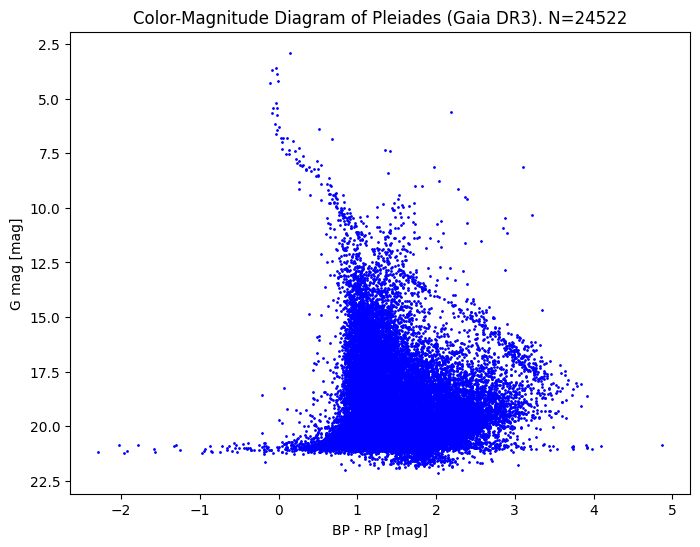

In [ ]:
# Convert to pandas DataFrame
df = results.to_table().to_pandas()
print(df.head())

# Plot 1: G magnitude vs. BP-RP color
plt.figure(figsize=(8,6))
plt.scatter(df['bp_rp'], df['phot_g_mean_mag'], s=1, color='blue')
plt.gca().invert_yaxis()
plt.xlabel('BP - RP [mag]')
plt.ylabel('G mag [mag]')
plt.title('Color-Magnitude Diagram of Pleiades (Gaia DR3). N={}'.format(len(df)))
plt.savefig('pleiades_cmd.pdf', dpi=300)
plt.show()

Plot proper motion vectors in the sky.

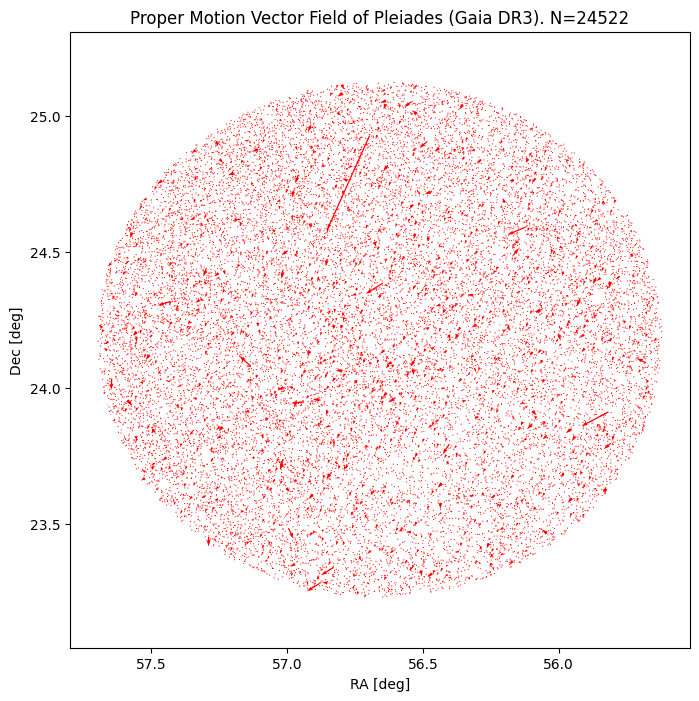

In [ ]:
# Plot 2: Proper motion vector field (using quiver with scaling)
plt.figure(figsize=(8,8))
scale_factor = 3e-4  # Adjust this factor to scale the arrows
plt.quiver(df['ra'], df['dec'], df['pmra']*scale_factor, df['pmdec']*scale_factor, angles='xy', scale_units='xy', scale=1, color='red', width=0.002)
plt.xlabel('RA [deg]')
plt.ylabel('Dec [deg]')
plt.gca().invert_xaxis()
plt.title('Proper Motion Vector Field of Pleiades (Gaia DR3). N={}'.format(len(df)))
plt.axis('equal')
plt.show()

Now we do a zoom around the center of Pleiades to better distinguish the vectors.

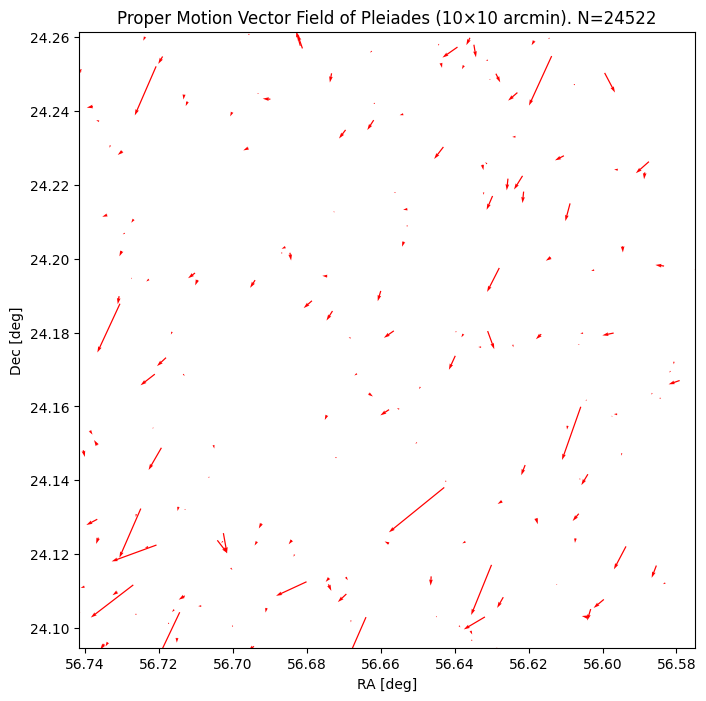

In [ ]:
# Plot 2 repeated: a zoom around the center of Pleiades
fig, ax = plt.subplots(figsize=(8, 8))
scale_factor = 3e-4  # Scale factor for proper motion arrows

# Conversion: 1 arcmin = 1/60 deg
half_size_deg = (10 / 60) / 2   # 10 arcmin total → ±5 arcmin around the center

# Plot the proper motion vectors
ax.quiver(df['ra'], df['dec'],
          df['pmra'] * scale_factor, df['pmdec'] * scale_factor,
          angles='xy', scale_units='xy', scale=1, color='red', width=0.002)

# Labels and title
ax.set_xlabel('RA [deg]')
ax.set_ylabel('Dec [deg]')
ax.set_title(f'Proper Motion Vector Field of Pleiades (10×10 arcmin). N={len(df)}')

# Define the field center
ra_center = pleiades_coord.ra.degree
dec_center = pleiades_coord.dec.degree

# Set axis limits (RA decreases to the right, Dec increases upward)
ax.set_xlim(ra_center + half_size_deg, ra_center - half_size_deg)  # RA inverted
ax.set_ylim(dec_center - half_size_deg, dec_center + half_size_deg)

# Keep the aspect ratio square (so the field is not distorted)
ax.set_aspect('equal')

plt.show()


Apparently, there is a number of stars with higher proper motions towards the southeast.

Let's see a diagram of proper motion _values_ in RA, Dec.

_Note the group of points around (20, -45) mas/yr._

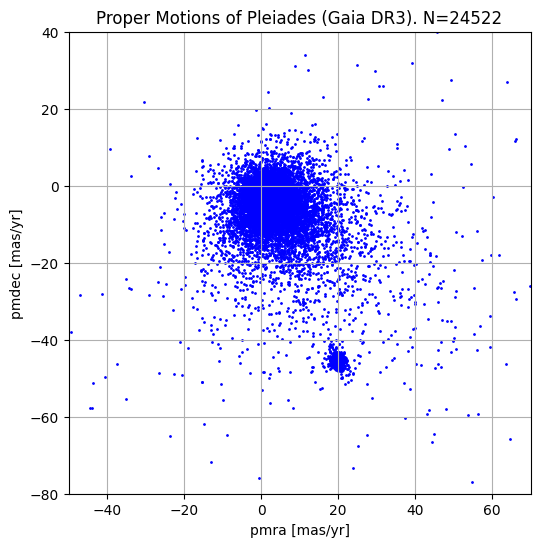

In [ ]:
# Plot 3: Proper motions in RA vs. Dec
plt.figure(figsize=(8,6))
plt.scatter(df['pmra'], df['pmdec'], s=1, color='blue')
plt.xlabel('pmra [mas/yr]')
plt.ylabel('pmdec [mas/yr]')
plt.xlim(-50, 70)
plt.ylim(-80, 40)
plt.title('Proper Motions of Pleiades (Gaia DR3). N={}'.format(len(df)))
plt.grid()
ax = plt.gca()
ax.set_aspect('equal', adjustable='box')
plt.savefig('pleiades_pm.pdf', dpi=300)
plt.show()

Create a group of comoving sources around (20, -45) mas/yr.

In [ ]:
# Select comoving sources
pm_mask = (
    (df['pmra'] > 15) &
    (df['pmra'] < 25) &
    (df['pmdec'] > -50) &
    (df['pmdec'] < -40)
)

comoving = df[pm_mask]
print(f"Number of comoving sources: {len(comoving)}")
print(comoving[['source_id', 'ra', 'dec', 'pmra', 'pmdec', 'phot_g_mean_mag']])

Number of comoving sources: 518

source_id         ra        dec       pmra      pmdec  \
54     65229734206151680  56.605873  24.159919  16.920656 -48.014607   
106    65226401312036864  56.630027  24.117141  18.379559 -45.251956   
108    66728265476081408  56.730558  24.187798  20.392591 -44.020638   
139    65225611037551360  56.663990  24.102995  20.529235 -46.941873   
143    65226092073881856  56.724916  24.132371  19.309048 -44.323806   
...                  ...        ...        ...        ...        ...   
24138  64960628735279232  56.710656  23.239000  18.082485 -40.430134   
24140  65089336018173440  55.907301  23.535788  19.527245 -45.292407   
24242  69846274292973056  56.525940  25.112610  16.415834 -40.418413   
24261  68317746971945600  55.790707  24.692314  23.192645 -48.135359   
24514  66847321969262464  56.813762  25.115240  20.304699 -41.129036   

       phot_g_mean_mag  
54           14.781489  
106          13.536427  
108          17.192360  
139           9.199545  
143          17.303078  
...                ...  
24138         9.784797  
24140        10.576324  
24242        15.486157  
24261        15.114011  
24514        15.495056  

[518 rows x 6 columns]

Repeat the color-magnitude diagram for the whole sample and the comoving stars.

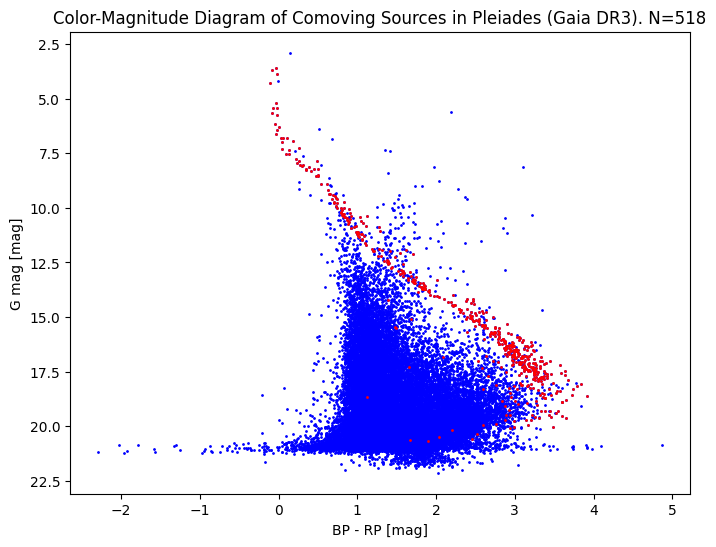

In [ ]:
# Repeat plot 1 (a CMD) for df and comoving sources
plt.figure(figsize=(8,6))
plt.scatter(df['bp_rp'], df['phot_g_mean_mag'], s=1, color='blue', label="All sources")
plt.scatter(comoving['bp_rp'], comoving['phot_g_mean_mag'], s=1, color='red', label="Comoving sources")
plt.gca().invert_yaxis()
plt.xlabel('BP - RP [mag]')
plt.ylabel('G mag [mag]')
plt.title('Color-Magnitude Diagram of Comoving Sources in Pleiades (Gaia DR3). N={}'.format(len(comoving)))
plt.savefig('pleiades_comoving_cmd.pdf', dpi=300)
plt.show()

# More PyVO: access to images

In this example we use pyVO to perform a Simple Image Access (SIA) query.


## Example 5: search and download an image

| Key function/method  | Description |
|----------------------|-------------|
| ```pyvo.regsearch``` | Do a query consulting the VO Registry. |
| ```pyvo.dat.SIAService``` | Definition of a Simple Image Access query |

Import the necessary packages

In [ ]:
# Import packages
import pyvo
from pyvo.dal.sia import SIAResults
import requests
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from astropy.table import Table
from astropy import units as u
from astropy.coordinates import SkyCoord, get_icrs_coordinates
from astropy.io import fits
from astropy.wcs import WCS
from astropy.io.votable import from_table
import subprocess

Define a function to plot an image from a 2D FITS file.

In [ ]:
# Function to plot a 2D FITS image

def plot_FITS(filename):
    from pathlib import Path
    from astropy.io import fits
    from astropy.wcs import WCS
    import matplotlib.pyplot as plt
    from astropy.visualization import ZScaleInterval, ImageNormalize

    # Open FITS file
    hdu = fits.open(filename)[0]
    data = hdu.data
    header = hdu.header

    # Get WCS information
    wcs = WCS(header)

    # Compute zscale normalization (automatic intensity range)
    interval = ZScaleInterval()
    vmin, vmax = interval.get_limits(data)
    norm = ImageNormalize(vmin=vmin, vmax=vmax)

    # Plot the FITS image with WCS projection
    fig = plt.figure()
    ax = fig.add_subplot(111, projection=wcs)
    im = ax.imshow(data, origin='lower', cmap='viridis', norm=norm)

    # Add coordinate grid and labels
    #ax.coords.grid(color='cyan', ls='--', lw=0.7, alpha=0.7)
    ax.set_xlabel('Right Ascension')
    ax.set_ylabel('Declination')

    # Custom formatter for the bottom-right status bar
    def format_coord(x, y):
        try:
            ra, dec = wcs.wcs_pix2world([[x, y]], 0)[0]
            return f"RA={ra:.6f}°  Dec={dec:.6f}°   Pixel=({x:.1f},{y:.1f})"
        except Exception:
            return f"Pixel=({x:.1f},{y:.1f})"

    ax.format_coord = format_coord

    plt.colorbar(im, ax=ax, orientation='vertical', label='Intensity')
    plt.title(Path(filename).name)
    plt.savefig(filename.replace('fits','pdf'))
    print(f"Image saved to {filename.replace('fits','pdf')}")
    plt.show()

Look for available services in the VO Registry.

In [ ]:
# It is possible to look for all the available (i.e. registered) SIA services
services = pyvo.regsearch(servicetype='sia', keywords=['image'])
print(f"Number of SIA services found: {len(services)}")

Number of SIA services found: 240

In [ ]:
# Too many results. Let's refine the search to the collections hosted by NOIRLab Data Lab
services = pyvo.regsearch(servicetype='sia', keywords=['noirlab'])
print(f"Number of SIA services found for NOIRLab: {len(services)}")

Number of SIA services found for NOIRLab: 64

In [ ]:
for pos, row in enumerate(services.to_table()):
    print(f"\nService {pos}: {row['res_title']}")
    if 'access_urls' in row.colnames:
        print(f"URL: {row['access_urls']}")
    else:
        print("No access_url found.")

Service 0: NSF NOIRLab - Astro Data Lab - All Instrument calibrated images

URL: https://datalab.noirlab.edu/sia/calibrated_all

Service 1: NSF NOIRLab - Astro Data Lab - DES Year-1 calibrated images

URL: https://datalab.noirlab.edu/sia/calibrated/des_y1

Service 2: NSF NOIRLab - Astro Data Lab - DES Year-2 calibrated images

URL: https://datalab.noirlab.edu/sia/calibrated/des_y2

... (118 outputs left out)

Service 62: NSF NOIRLab - Astro Data Lab - S-PLUS DR1 images in Stripe82

URL: https://datalab.noirlab.edu/sia/stripe82/splus_dr1

Service 63: NSF NOIRLab - Astro Data Lab - S-PLUS EDR images in Stripe82

URL: https://datalab.noirlab.edu/sia/stripe82/splus_edr

> **⚠️ Warning**

> The field found as ```access_urls``` in colab may appear as ```access_url``` if you run the code in a terminal.

> _Take it into account in your daily work._

Select the "coadd images" service (10th in the list)

In [ ]:
# Select coadded images from NOIRLab Data Lab
coadd_service = services.to_table()[9]
print(f"Selected service: {coadd_service['res_title']}")
SERVICE_URL = coadd_service['access_urls']
service = pyvo.dal.SIAService(SERVICE_URL)
print(f"URL: {SERVICE_URL}")

Selected service: NSF NOIRLab - Astro Data Lab - All coadded images

URL: https://datalab.noirlab.edu/sia/coadd_all

Find the coordinates and do the query.

In [ ]:
# Find coordinates of a source from its name
TARGET = 'Horsehead Nebula'
target_coords = get_icrs_coordinates(TARGET)
# Convenience:
target_coords = SkyCoord.from_name(TARGET)
target_ra = target_coords.ra.degree
target_dec = target_coords.dec.degree
radius = 0.25*u.deg    # radius may be specified using astropy units
print("\n-------------------------------------------------------------")
print(f"Target coordinates: (RA, Dec)=({target_coords.ra.degree:5f}, Dec={target_coords.dec.degree:5f}). Search radius: {radius}")

-------------------------------------------------------------

Target coordinates: (RA, Dec)=(85.245833, Dec=-2.458333). Search radius: 0.25 deg

In [ ]:
# Do the query
images = service.search(target_coords, size=(radius,radius))

# results works similarly to an astropy Table
print(f"Number of images: {len(images)}")

Number of images: 70

Inspect the results.

In [ ]:
# Inspect the column names
images_table = images.to_table()
print(images_table.colnames)  # List of column names

[
    'assoc_id',
    'access_url',
    'access_format',
    'access_estsize',
    'dataproduct_type',
    'dataproduct_subtype',
    'calib_level',
    'dataset_length',
    'im_nsubarrays',
    'im_naxes',
    'im_naxis',
    'im_pixtype',
    'im_wcsaxes',
    'im_scale',
    'obs_title',
    'obs_id',
    'obs_creator_name',
    'obs_collection',
    'obs_creation_type',
    'obs_creation_date',
    'facility_name',
    'instrument_name',
    'obs_bandpass',
    'obs_datasource',
    'proposal_id',
    'obs_publisher_did',
    'obs_release_date',
    'preview',
    'target_name',
    'target_class',
    's_ra',
    's_dec',
    's_fov',
    's_region',
    's_calib_status',
    's_resolution',
    'em_min',
    'em_max',
    'em_resolution',
    'em_res_power',
    't_min',
    't_max',
    't_exptime',
    't_resolution',
    'o_ucd',
    'o_unit',
    'pol_states',
    'object',
    'airmass',
    'project_code',
    'magzero',
    'prodtype',
    'seeing',
    'fwhm',
    'fileset_id',
    'exptime',
    'photflag',
    'proctype',
    'date_obs',
    'mjd_obs',
    'elliptic'
]

In [ ]:
# Note that not all the 'prodtype' are 'image'.
prodtypes = set(images_table['prodtype'])
print(f"Product types in the results: {prodtypes}")

Product types in the results: {'expmap', 'wtmap', 'dqmask', 'image'}

Convert to VOTable and save results.

In [ ]:
# Convert to VOTable
images_vot = images.votable

# Print all the fields (i.e. columns)
for field in images_vot.iter_fields_and_params():
    print(f"Field/Param: {field.name}")

# Save query results to a local VOTable file
images_table.write('images.vot', format='votable', overwrite=True)
print("\n-------------------------------------------------------------")
print("Results saved to images.vot")

Field/Param: assoc_id

Field/Param: access_url

Field/Param: access_format

Field/Param: access_estsize

Field/Param: dataproduct_type

Field/Param: dataproduct_subtype

... (57 outputs left out)

Field/Param: datamodel_name

Field/Param: datamodel_prefix

-------------------------------------------------------------

Results saved to images.vot

Download and plot one of the images.

In [ ]:
# Access and download one image
horsehead = images[21]
image_url = horsehead.getdataurl()
print(f"Selected image data URL: {image_url}")
response = requests.get(image_url)
with open('horsehead.fits', 'wb') as f:
    f.write(response.content)
print("\n-------------------------------------------------------------")
print("Selected image downloaded as horsehead.fits")

Selected image data URL: 
https://datalab.noirlab.edu/svc/cutout?col=&siaRef=c4d_141208_064909_osi_r_v1.fits.fz&extn=4&POS=85.24583333,-2.458
33333&SIZE=0.25,0.25

-------------------------------------------------------------

Selected image downloaded as horsehead.fits

Image saved to horsehead.pdf

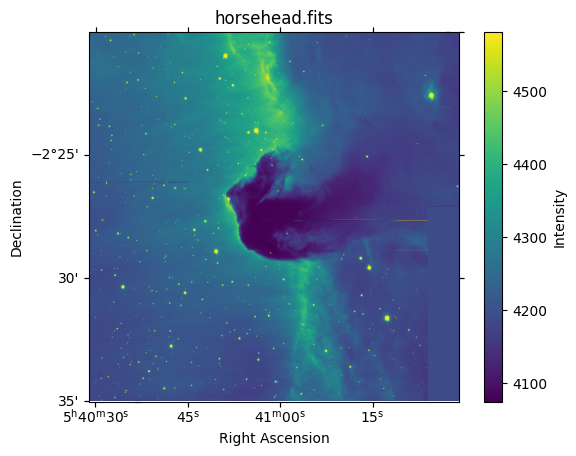

In [ ]:
plot_FITS('horsehead.fits')

# Diving deep inside VO: the Registry
Most of the Virtual Observatory resources are available through the VO Registry: a compilation of metadata and applications to access them.

In this example we do a query of spectroscopic data by a direct request to the Registry.

## Example 6: explore PyVO capabilites searching the Registry for spectra.

| Key function/method  | Description |
|----------------------|-------------|
| ```pyvo.regsearch``` | Convenience function to do a query to the VO Registry. |
| ```pyvo.dat.SSAService``` | Definition of a Simple Spectral Access query |

Import the necessary packages

In [ ]:
import pyvo
from pyvo import registry
from rich import print
import requests
import matplotlib.pyplot as plt
from astropy.table import Table
from astropy.coordinates import SkyCoord

Start by searching all the catalogs available through the Simple Spectral Access (SSA) protocol.

In [ ]:
# Search for Simple Spectral Access (SSA) services using pyVO regsearch convenience function
services = pyvo.regsearch(servicetype='ssa')
print(f"Number of Simple Spectral Access services found: {len(services)}")

Number of Simple Spectral Access services found: 184

Too many results.

Let's refine the search to services related to LAMOST

In [ ]:
# Search only to LAMOST using PyVO registry method
ssa_lamost_services = registry.search(servicetype="ssa", keywords="LAMOST")
type(ssa_lamost_services)

# Print number of services found
print(f"Number of SSA services related to LAMOST: {len(ssa_lamost_services)}")

Number of SSA services related to LAMOST: 7

Look at some details about the services found.

In [ ]:
# Title of the services and URLs to access them
pos = 0
for s in ssa_lamost_services:
    print(f"Service {pos}: {s['res_title']}")
    try:
        print(f"Access URLs: {s['access_urls']}")
    except KeyError:
        print("No access_urls found.")
    pos += 1


Service 0: LAMOST DR1 survey spectra

Access URLs: ['http://vos2.asu.cas.cz/lamost_dr1/q/ssa/ssap.xml?']

Service 1: LAMOST DR2 survey spectra

Access URLs: ['http://vos2.asu.cas.cz/lamost_dr2/q/ssa/ssap.xml?']

Service 2: LAMOST DR3 survey spectra

Access URLs: ['http://vos2.asu.cas.cz/lamost_dr3/q/ssa/ssap.xml?']

... (4 outputs left out)

Service 5: LAMOST DR6 Low Resolution Spectra

Access URLs: ['http://dc.g-vo.org/lamost6/q/svc_lrs/ssap.xml?']

Service 6: LAMOST DR6 Medium Resolution Spectra

Access URLs: ['http://dc.g-vo.org/lamost6/q/svc_mrs/ssap.xml?']

Select the last service (LAMOST DR6)

In [ ]:
# Select the last service (LAMOST DR6)
lamost_dr6 = ssa_lamost_services[-1]
print(f"Selected LAMOST DR6 MRS service title: {lamost_dr6['res_title']}")

for col,val in lamost_dr6.items():
    print(f"{col}: {val}")

Selected LAMOST DR6 MRS service title: LAMOST DR6 Medium Resolution Spectra

ivoid: ivo://org.gavo.dc/lamost6/q/svc_mrs

res_type: vs:catalogservice

short_name: LM6 MRS SSAP

res_title: LAMOST DR6 Medium Resolution Spectra

content_level: research

... (12 outputs left out)

standard_ids: ['ivo://ivoa.net/std/ssa']

intf_types: ['vs:paramhttp']

intf_roles: ['std']

cap_descriptions: []

Build the service and do the query

In [ ]:
# Get the URL from the previous request
# query_url = lamost_dr6['access_urls']
query_url = lamost_dr6['access_urls'][0] # Extract the first URL from the list
print(f"Query URL: {query_url}")

# Build the service object
lamost_service = pyvo.dal.SSAService(query_url)
print(f"SSAService object created: {lamost_service}")

# Performing the query
spectra = lamost_service.search(pos=(180.0, 0.0), diameter=3.)

# Alternatively, try with a source name
#pos = SkyCoord.from_name('VY CMa')
#spectra = lamost_service.search(pos=pos, diameter=3.)
print(f"Number of results from LAMOST DR6 MRS query: {len(spectra)}")

Query URL: http://dc.g-vo.org/lamost6/q/svc_mrs/ssap.xml?

SSAService object created: SSAService(baseurl : 'http://dc.g-vo.org/lamost6/q/svc_mrs/ssap.xml?', description : 
'None')

Number of results from LAMOST DR6 MRS query: 1522

Manipulate the results and save the table

In [ ]:
# Convert results to an Astropy Table
spectra_table = spectra.to_table()
print(spectra_table)

# Convert to VOTable and write to file
spectra_vot = spectra.votable
spectra_vot.to_xml('lamost_dr6_spectra.vot')
print("\n-------------------------------------------------------------")
print("Results saved to lamost_dr6_spectra.vot")

ssa_score ...                              preview                             
          ...                                                                  
--------- ... -----------------------------------------------------------------
      0.0 ... http://dc.g-vo.org/getproduct/lamost6/mrs/638701196B?preview=True
      0.0 ... http://dc.g-vo.org/getproduct/lamost6/mrs/638701196R?preview=True
      0.0 ... http://dc.g-vo.org/getproduct/lamost6/mrs/638701193B?preview=True
      0.0 ... http://dc.g-vo.org/getproduct/lamost6/mrs/638701193R?preview=True
      0.0 ... http://dc.g-vo.org/getproduct/lamost6/mrs/638707166B?preview=True
      0.0 ... http://dc.g-vo.org/getproduct/lamost6/mrs/638707166R?preview=True
      0.0 ... http://dc.g-vo.org/getproduct/lamost6/mrs/638707243B?preview=True
      0.0 ... http://dc.g-vo.org/getproduct/lamost6/mrs/638707243R?preview=True
      0.0 ... http://dc.g-vo.org/getproduct/lamost6/mrs/638707151B?preview=True
      ... ...                                                               ...
      0.0 ... http://dc.g-vo.org/getproduct/lamost6/mrs/653107085B?preview=True
      0.0 ... http://dc.g-vo.org/getproduct/lamost6/mrs/653107085R?preview=True
      0.0 ... http://dc.g-vo.org/getproduct/lamost6/mrs/626207150B?preview=True
      0.0 ... http://dc.g-vo.org/getproduct/lamost6/mrs/626207150R?preview=True
      0.0 ... http://dc.g-vo.org/getproduct/lamost6/mrs/637607150B?preview=True
      0.0 ... http://dc.g-vo.org/getproduct/lamost6/mrs/637607150R?preview=True
      0.0 ... http://dc.g-vo.org/getproduct/lamost6/mrs/653107150B?preview=True
      0.0 ... http://dc.g-vo.org/getproduct/lamost6/mrs/653107150R?preview=True
      0.0 ... http://dc.g-vo.org/getproduct/lamost6/mrs/626207139B?preview=True
      0.0 ... http://dc.g-vo.org/getproduct/lamost6/mrs/626207139R?preview=True
Length = 1522 rows

-------------------------------------------------------------

Results saved to lamost_dr6_spectra.vot

Select and save one spectrum from the results.

In [ ]:
# Select one spectrum and download data
k = 690  # Index of the spectrum to download
spectrum = spectra[k]
spectrum_url = spectrum.getdataurl()
print(f"Spectrum data URL: {spectrum_url}")
response = requests.get(spectrum_url)

# response is natively a VOTable file
with open('lamost_spectrum.vot', 'wb') as f:
    f.write(response.content)
print("\n-------------------------------------------------------------")
print("Spectrum saved to lamost_spectrum.vot")

Spectrum data URL: http://dc.g-vo.org/getproduct/lamost6/mrs/626205246B

-------------------------------------------------------------

Spectrum saved to lamost_spectrum.vot

Load the spectrum, plot it and save the figure.

-------------------------------------------------------------

Spectrum saved to lamost_spectrum.pdf

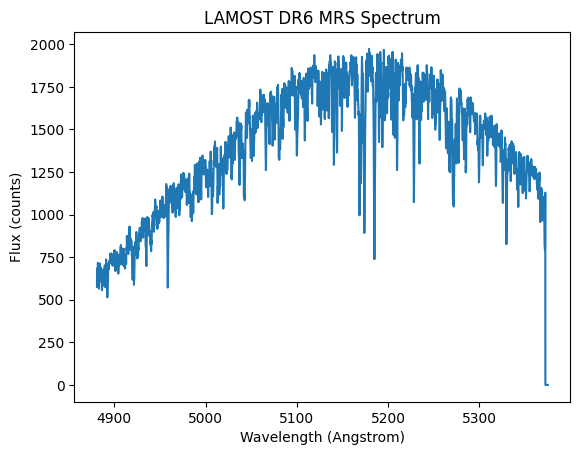

In [ ]:

# Load the spectrum and plot it
spectrum_table = Table.read('lamost_spectrum.vot')
plt.plot(spectrum_table['spectral'], spectrum_table['flux'])
plt.xlabel('Wavelength (Angstrom)')
plt.ylabel('Flux (counts)')
plt.title('LAMOST DR6 MRS Spectrum')
plt.savefig('lamost_spectrum.pdf', dpi=300)
print("\n-------------------------------------------------------------")
print("Spectrum saved to lamost_spectrum.pdf")
plt.show()

# A sophisticated query using TAP

In this example we query tha Gaia DR3 dataset to download those records matching _several_ conditions, instead of filtering a large table after downloading it.

## Example 7: Tailored query of the Gaia DR3 archive.

| Key function/method  | Description |
|----------------------|-------------|
| ```pyvo.dal.TAPService``` | Class to instantiate a TAP service and include its methods and functions.

**Reference:** this example is adapted from the Mas-Buitrago's et al. (2024) tutorial in [zenodo](https://zenodo.org/records/14226117).

Import the necessary packages

In [ ]:
import pyvo
import matplotlib.pyplot as plt
from rich import print
from astropy import units as u
from astropy.coordinates import SkyCoord

Create the instance to the Gaia TAP service

In [ ]:
tap_gaia = pyvo.dal.TAPService("https://gea.esac.esa.int/tap-server/tap")

Start with a generic query

In [ ]:
# Define a query to the Gaia endpoint to get information about the available tables (schemas, types)
query = '''
SELECT DISTINCT schema_name, table_type
FROM tap_schema.tables
'''

# Execute the query and get the results as an Astropy Table
gaia_info = tap_gaia.search(query).to_table()
print(gaia_info)

schema_name table_type
----------- ----------
   external      table
    gaiadr1      table
    gaiadr2      table
    gaiadr3      table
   gaiaedr3      table
    gaiafpr      table
     public      table
 tap_config      table
 tap_schema      table

Define a query to the selected Gaia endpoint to get information about tables in the 'gaiadr3' schema related to 'source'


In [ ]:
query = '''
SELECT table_name, schema_name, size, table_type
FROM tap_schema.tables
WHERE schema_name = 'gaiadr3'
AND table_name LIKE '%source%'
AND table_type = 'table'
'''

Execute the query and get the results as an Astropy Table

In [ ]:
gaia_info = tap_gaia.search(query).to_table()
print(gaia_info)

table_name            schema_name    size    table_type
-------------------------------- ----------- ---------- ----------
  gaiadr3.gaia_source_simulation     gaiadr3 1644237695      table
    gaiadr3.frame_rotator_source     gaiadr3     429249      table
        gaiadr3.gaia_source_lite     gaiadr3 1811709771      table
gaiadr3.alerts_mixedin_sourceids     gaiadr3         94      table
              gaiadr3.sso_source     gaiadr3     158152      table
             gaiadr3.gaia_source     gaiadr3 1811709771      table

Define and execute a query to get data from the gaiadr3.gaia_source table.

Coordinates selected correspond to the open cluster M67. Note the conditions applied to the query.

In [ ]:
# query for M67
OBJECT_NAME = 'M67'
SEARCH_RADIUS = 0.5*u.deg
coords = SkyCoord.from_name(OBJECT_NAME)
print(f"\nCoordinates of {OBJECT_NAME}: RA={coords.ra.deg} deg, Dec={coords.dec.deg} deg")
query = '''
SELECT TOP 5000 *
FROM gaiadr3.gaia_source
WHERE parallax_over_error > 10
AND ABS(pmra_error/pmra) < 0.1
AND ABS(pmdec_error/pmdec) < 0.1
AND pmra < -10.44
AND pmra > -11.44
AND pmdec < -2.39
AND pmdec > -3.39
AND 1=CONTAINS(
  POINT(ra,dec),
  CIRCLE(132.848,11.815,0.5))
'''

# Execute the query and get the results as an Astropy Table
gaia_data = tap_gaia.search(query).to_table()
print(gaia_data)

Coordinates of M67: RA=132.848 deg, Dec=11.815 deg

solution_id             designation         ... libname_gspphot
                                                ...                
------------------- --------------------------- ... ---------------
1636148068921376768 Gaia DR3 598695763635752448 ...           MARCS
1636148068921376768 Gaia DR3 598696077168308992 ...           MARCS
1636148068921376768 Gaia DR3 598697142320464384 ...           MARCS
1636148068921376768 Gaia DR3 598883337742544128 ...           MARCS
1636148068921376768 Gaia DR3 598884295519951616 ...           MARCS
1636148068921376768 Gaia DR3 598884746491793024 ...                
1636148068921376768 Gaia DR3 598884952650222336 ...           MARCS
1636148068921376768 Gaia DR3 598885738628962432 ...           MARCS
1636148068921376768 Gaia DR3 598885880363159296 ...         PHOENIX
                ...                         ... ...             ...
1636148068921376768 Gaia DR3 605001462821192960 ...         PHOENIX
1636148068921376768 Gaia DR3 605001707634588544 ...         PHOENIX
1636148068921376768 Gaia DR3 605002016872204416 ...           MARCS
1636148068921376768 Gaia DR3 605002600987738496 ...           MARCS
1636148068921376768 Gaia DR3 605003013304624128 ...         PHOENIX
1636148068921376768 Gaia DR3 605004387694123136 ...           MARCS
1636148068921376768 Gaia DR3 605005418486272896 ...           MARCS
1636148068921376768 Gaia DR3 605005620348847488 ...         PHOENIX
1636148068921376768 Gaia DR3 605013767903055616 ...           MARCS
1636148068921376768 Gaia DR3 605015309794935552 ...                
Length = 824 rows

Plot a color-magnitude diagram and save data

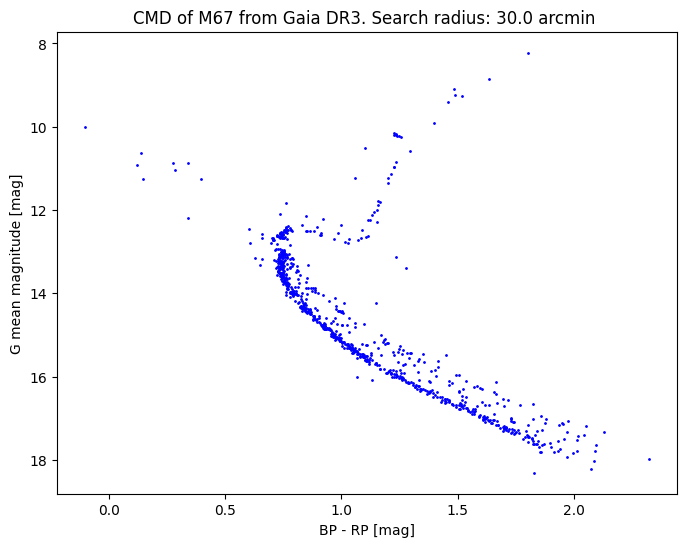

-------------------------------------

Gaia data saved to gaia_m67.vot

In [ ]:
# Plot a CMD using matplotlib
plt.figure(figsize=(8, 6))
plt.scatter(gaia_data['bp_rp'], gaia_data['phot_g_mean_mag'], s=1, color='blue')
plt.gca().invert_yaxis()  # Invert y-axis for magnitude
plt.xlabel('BP - RP [mag]')
plt.ylabel('G mean magnitude [mag]')
plt.title(f"CMD of {OBJECT_NAME} from Gaia DR3. Search radius: {SEARCH_RADIUS.to(u.arcmin)} ")
plt.savefig('cmd_gaia_m67.pdf', dpi=300)
plt.show()

# Save data to a VOTable file
gaia_data.write('gaia_m67.vot', format='votable', overwrite=True)
print("\n-------------------------------------")
print("Gaia data saved to gaia_m67.vot")